In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import rosel.io
import rosel.computation
import rosel.shiroma

In [3]:
type, n_jobs, job_memory = ["LOCAL", 22, None]
client = rosel.computation.create_client(type, n_jobs, job_memory)

2025-02-24 12:17:24 [debug    ] <Cluster info: type=LOCAL, n_jobs=22, job_memory=2181376828>


In [4]:
in_path = rosel.io.normpath("/home/morea/SAOCOM/")
slc_path = f"{in_path}/INPUT_DATA/slcs.zarr"
acquisition_date = "2023-12-12"
wdir_path = f"{in_path}/WDIR_DATA/{acquisition_date}"
selection_path = f"{wdir_path}/selection"
rtc_ap_path = f"{wdir_path}/rtc_ap"

In [5]:
slc = rosel.io.read(slc_path).orig[acquisition_date].measurements.slc.squeeze()
selection = rosel.io.read(selection_path)
A = rosel.io.read(rtc_ap_path, mask_and_scale=False).v

## Full Resolution

In [6]:
# testing the amplitude
c = np.abs(slc).drop_vars(slc.coords)

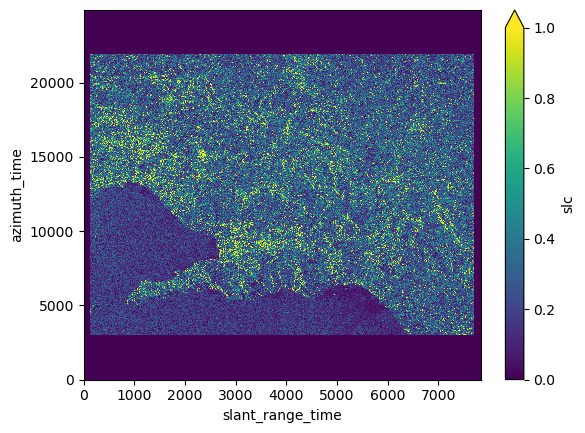

In [7]:
c.plot(vmin=0, vmax=1.0)

In [8]:
c_gamma = rosel.shiroma.flatten_radar_image(c, A, data_path=wdir_path, data_name="flattened_amplitude", read=True)

2025-02-24 12:18:40 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-24 12:18:40 [debug    ] Number of blocks to be processed: 200


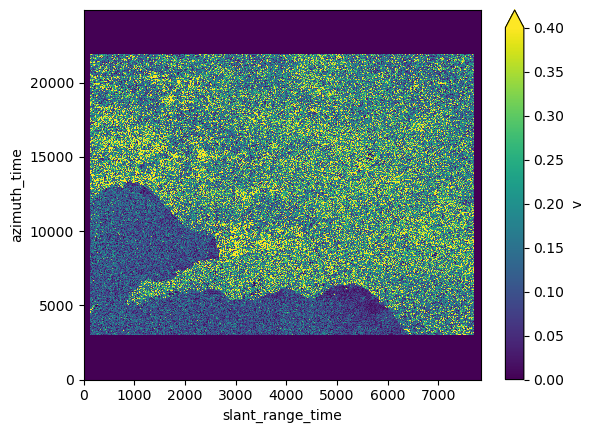

In [9]:
np.abs(c_gamma).plot(vmin=0, vmax=0.4)

In [10]:
g = rosel.shiroma.map_geo_ap(
    f"{wdir_path}/flattened_amplitude",
    selection,
    wdir_path,
    data_name="geo_ap",
    read=True,
    enable_dask=True,
)

2025-02-24 12:20:03 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-24 12:20:03 [debug    ] Number of blocks to be processed: 5184


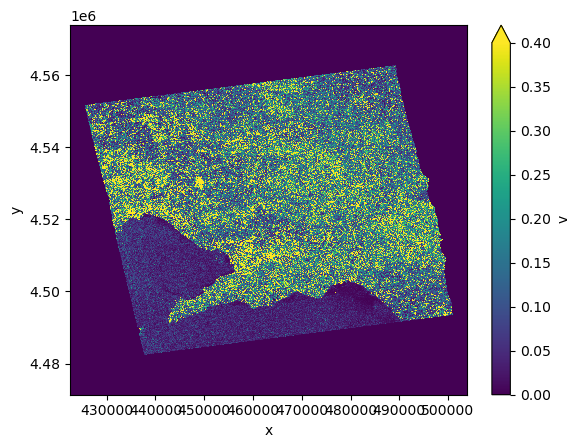

In [11]:
(np.abs(g) ** 2).plot(vmin=0, vmax=0.4)

## Multilooked image

In [12]:
multilook = {"azimuth_time": 3, "slant_range_time": 5}

In [13]:
c_ml = (
    c.coarsen(azimuth_time=multilook["azimuth_time"], slant_range_time=multilook["slant_range_time"], boundary="pad")
    .mean()
    .chunk(azimuth_time=300, slant_range_time=300)
)

In [14]:
c_gamma_ml = rosel.shiroma.flatten_radar_image(
    c_ml, A, multilook=multilook, data_path=wdir_path, data_name="flattened_amplitude_ml", read=True
)

2025-02-24 12:22:05 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-24 12:22:05 [debug    ] Number of blocks to be processed: 168


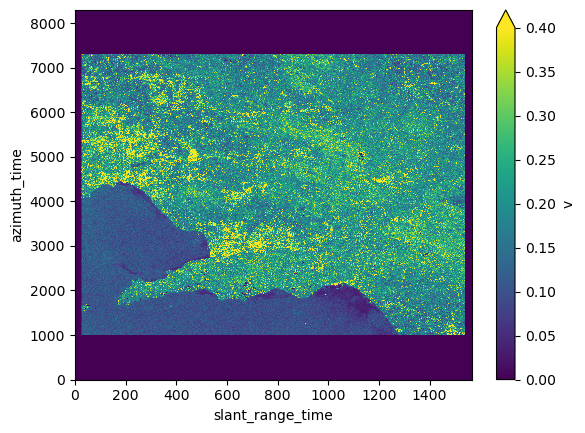

In [15]:
np.abs(c_gamma_ml).plot(vmin=0, vmax=0.4)

In [17]:
g_ml = rosel.shiroma.map_geo_ap(
    c_path=f"{wdir_path}/flattened_amplitude_ml",
    simulation=selection,
    data_path=wdir_path,
    multilook=multilook,
    data_name="geo_ap_ml",
    read=True,
    enable_dask=True,
)

2025-02-24 12:22:17 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-24 12:22:17 [debug    ] Number of blocks to be processed: 5184


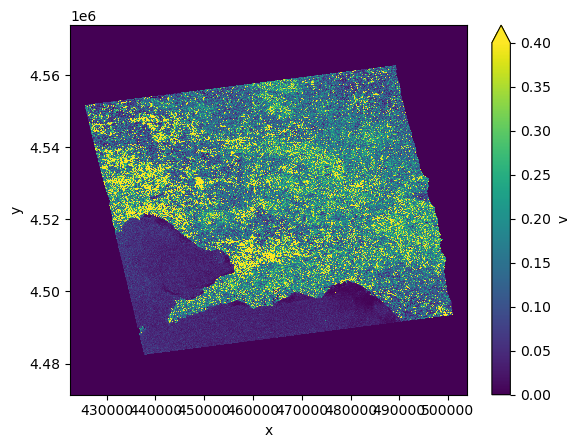

In [19]:
(np.abs(g_ml) ** 2).plot(vmin=0, vmax=0.4)